In [93]:
# Standard imports
import numpy as np
import scipy
import matplotlib.pyplot as plt

import pickle
import os
from copy import deepcopy

import at

import utils as u

from importlib import reload
reload(u.plot);
reload(u.at);

In [18]:
with open('candidates/v01_01_03_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

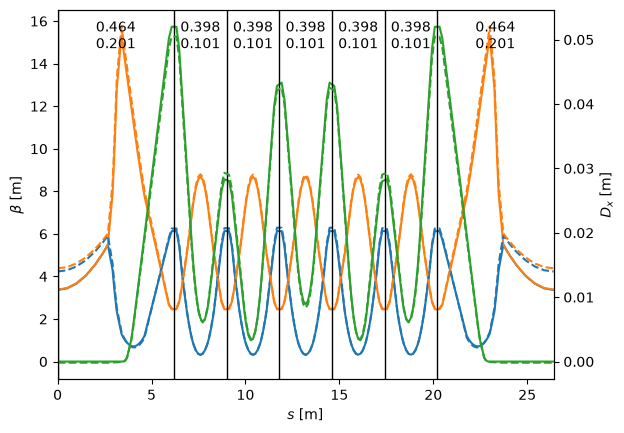

In [162]:
def align_twin(ax, twin, padding=0.05):
    """ Aligns the zeroes of a main and twin axes. """
    # Get data limits with padding
    y1_min, y1_max = ax.dataLim.intervaly
    y2_min, y2_max = twin.dataLim.intervaly

    p1 = padding * (y1_max - y1_min)
    p2 = padding * (y2_max - y2_min)
    y1_min, y1_max = y1_min - p1, y1_max + p1
    y2_min, y2_max = y2_min - p2, y2_max + p2

    # Fraction of axis height below zero
    f = np.clip(max(
        -y1_min / (y1_max - y1_min),
        -y2_min / (y2_max - y2_min),
    ), 0, 1)

    # Expand limits to align zeroes
    span1 = max(
        y1_max / (1 - f) if f < 1 else 0,
        -y1_min / f if f > 0 else 0,
    )
    span2 = max(
        y2_max / (1 - f) if f < 1 else 0,
        -y2_min / f if f > 0 else 0,
    )

    ax.set_ylim(-f * span1, (1 - f) * span1)
    twin.set_ylim(-f * span2, (1 - f) * span2)


def linear(ring: at.lattice, ring0='TDR-1', ax=None, twin=None, UC_tunes=True, **kwargs):
    if ax is None:
        fig, ax = plt.subplots()
        twin = ax.twinx()

    """ Calculation """
    elemdata = at.linopt4(ring, at.All)[2]
    s = elemdata.s_pos

    """ Plotting """
    ax.plot(s, elemdata.beta[:, 0], c='tab:blue', **kwargs)
    ax.plot(s, elemdata.beta[:, 1], c='tab:orange', **kwargs)
    twin.plot(s, elemdata.dispersion[:, 0], c='tab:green', **kwargs)
    # twin.plot(s, 200*H/Jx, c='tab:red', **kwargs)

    ax.set_xlabel(r'$s$ [m]')
    ax.set_ylabel(r'$\beta$ [m]')
    twin.set_ylabel(r'$D_x$ [m]')

    """ Unit cell tunes """
    index_UC = at.get_uint32_index(ring, 'UCborder')

    if 0 not in index_UC:
        index_UC = np.array([0, *index_UC])
        
    if len(ring) not in index_UC:
        index_UC = np.array([*index_UC, len(ring)])


    if UC_tunes and len(index_UC) >= 2:
        for i, index in enumerate(index_UC):

            if i != len(index_UC)-1: 
                plt.axvline(s[index], linewidth=1, color='black')
            if i != 0:  
                Q_UC = np.round((elemdata.mu[index] - elemdata.mu[index_UC[i-1]])/(2*np.pi), 3)
                s_mid = np.mean(s[index_UC[i-1:i+1]])
                ax.text(s_mid, ax.get_ylim()[1], f'{Q_UC[0]}\n{Q_UC[1]}', ha='center', va='top')

    # Axis limits
    ax.set_xlim(s.min(), s.max())
    align_twin(ax, twin)

    """ Plot baseline """
    if ring0 is not None:
        if ring0 == 'TDR-1':
            with open('candidates/n01_02_01_01/ring.pkl', 'rb') as file:
                ring0 = pickle.load(file)

        linear(ring0, None, ax, twin, UC_tunes=False, ls='--')

    return ax, twin

with open('candidates/v01_01_03_01/ring.pkl', 'rb') as file:
    ring = pickle.load(file)

ax, twin = linear(ring)